---
Lesson 5
---

Within this weeks lesson, we will look at how to break a Vigenère Cipher. Then we will look at our first unbreakable cipher, and finish off by talking about other areas of cryptography which you may want to look into (but we do not have time during our lessons).

# Section 1: Breaking the Vigenère Cipher

For those of you that attended the lesson last week, I briefly explained how to break the Vigenère Cipher (although I did not explain it very well).

The Vigenère Cipher was first broken publicly by Friedrich Kasiski in 1863 (although Charles Babbage solved it in 1854 and kept it secret). It was broken because of how the keyword is repeated. We know that 'the' is the most common English trigram by a significant amount, which means that 'the' has a higher chance of being encrypted by the same 3 letters in the ciphertext than other trigrams. So there are some trigrams that repeat a lot more than others within the ciphertext, more than randomness would predict. We can then count the number of letters between each trigram in the text. If you then take all the distances between the trigrams, then the keyword length is likely to be the greatest common divisor of these distances. We can see how this works in an example.

### Example 1

I have encrypted a large piece of text using a Vigenère Cipher. We can now see if we can break this cipher and discover the keyword.

In [2]:
#| echo: false

# ============================================================
# Vigenere cipher encryption
# ============================================================
# Encryption rule:  c = (p + k) mod 26
# where k is the shift given by the current key letter (A=0, B=1, ... Z=25).
# The key repeats along the message.
# ============================================================

# ---- Choose your key here ----

key = "Gruel"

# ---- Paste your book extract here ----
plaintext = """
Among other public buildings in a certain town, which for many reasons it will be prudent to refrain from mentioning, and to which I will assign no fictitious name, there is one anciently common to most towns, great or small: to wit, a workhouse; and in this workhouse was born; on a day and date which I need not trouble myself to repeat, inasmuch as it can be of no possible consequence to the reader, in this stage of the business at all events; the item of mortality whose name is prefixed to the head of this chapter.

For a long time after it was ushered into this world of sorrow and trouble, by the parish surgeon, it remained a matter of considerable doubt whether the child would survive to bear any name at all; in which case it is somewhat more than probable that these memoirs would never have appeared; or, if they had, that being comprised within a couple of pages, they would have possessed the inestimable merit of being the most concise and faithful specimen of biography, extant in the literature of any age or country.

Although I am not disposed to maintain that being born in a workhouse, is in itself the most fortunate and enviable circumstance that can possibly befall a human being, I do mean to say that in this particular instance, it was the best thing for Oliver Twist that could by possibility have occurred. The fact is, that there was considerable difficulty in inducing Oliver to take upon himself the office of respiration,—a troublesome practice, but one which custom has rendered necessary to our easy existence; and for some time he lay gasping on a little flock mattress, rather unequally poised between this world and the next: the balance being decidedly in favour of the latter. Now, if, during this brief period, Oliver had been surrounded by careful grandmothers, anxious aunts, experienced nurses, and doctors of profound wisdom, he would most inevitably and indubitably have been killed in no time. There being nobody by, however, but a pauper old woman, who was rendered rather misty by an unwonted allowance of beer; and a parish surgeon who did such matters by contract; Oliver and Nature fought out the point between them. The result was, that, after a few struggles, Oliver breathed, sneezed, and proceeded to advertise to the inmates of the workhouse the fact of a new burden having been imposed upon the parish, by setting up as loud a cry as could reasonably have been expected from a male infant who had not been possessed of that very useful appendage, a voice, for a much longer space of time than three minutes and a quarter.

As Oliver gave this first proof of the free and proper action of his lungs, the patchwork coverlet which was carelessly flung over the iron bedstead, rustled; the pale face of a young woman was raised feebly from the pillow; and a faint voice imperfectly articulated the words, “Let me see the child, and die.”

The surgeon had been sitting with his face turned towards the fire: giving the palms of his hands a warm and a rub alternately. As the young woman spoke, he rose, and advancing to the bed’s head, said, with more kindness than might have been expected of him:

“Oh, you must not talk about dying yet.”

“Lor bless her dear heart, no!” interposed the nurse, hastily depositing in her pocket a green glass bottle, the contents of which she had been tasting in a corner with evident satisfaction.

“Lor bless her dear heart, when she has lived as long as I have, sir, and had thirteen children of her own, and all on ’em dead except two, and them in the wurkus with me, she’ll know better than to take on in that way, bless her dear heart! Think what it is to be a mother, there’s a dear young lamb, do.”

Apparently this consolatory perspective of a mother’s prospects failed in producing its due effect. The patient shook her head, and stretched out her hand towards the child.

The surgeon deposited it in her arms. She imprinted her cold white lips passionately on its forehead; passed her hands over her face; gazed wildly round; shuddered; fell back—and died. They chafed her breast, hands, and temples; but the blood had stopped forever. They talked of hope and comfort. They had been strangers too long.

“It’s all over, Mrs. Thingummy!” said the surgeon at last.

“Ah, poor dear, so it is!” said the nurse, picking up the cork of the green bottle, which had fallen out on the pillow, as she stooped to take up the child. “Poor dear!”

“You needn’t mind sending up to me, if the child cries, nurse,” said the surgeon, putting on his gloves with great deliberation. “It’s very likely it will be troublesome. Give it a little gruel if it is.” He put on his hat, and, pausing by the bed-side on his way to the door, added, “She was a good-looking girl, too; where did she come from?”

“She was brought here last night,” replied the old woman, “by the overseer’s order. She was found lying in the street. She had walked some distance, for her shoes were worn to pieces; but where she came from, or where she was going to, nobody knows.”

The surgeon leaned over the body, and raised the left hand. “The old story,” he said, shaking his head: “no wedding-ring, I see. Ah! Good-night!”

The medical gentleman walked away to dinner; and the nurse, having once more applied herself to the green bottle, sat down on a low chair before the fire, and proceeded to dress the infant.

What an excellent example of the power of dress, young Oliver Twist was! Wrapped in the blanket which had hitherto formed his only covering, he might have been the child of a nobleman or a beggar; it would have been hard for the haughtiest stranger to have assigned him his proper station in society. But now that he was enveloped in the old calico robes which had grown yellow in the same service, he was badged and ticketed, and fell into his place at once—a parish child—the orphan of a workhouse—the humble, half-starved drudge—to be cuffed and buffeted through the world—despised by all, and pitied by none.

Oliver cried lustily. If he could have known that he was an orphan, left to the tender mercies of churchwardens and overseers, perhaps he would have cried the louder.

For the next eight or ten months, Oliver was the victim of a systematic course of treachery and deception. He was brought up by hand. The hungry and destitute situation of the infant orphan was duly reported by the workhouse authorities to the parish authorities. The parish authorities inquired with dignity of the workhouse authorities, whether there was no female then domiciled in “the house” who was in a situation to impart to Oliver Twist, the consolation and nourishment of which he stood in need. The workhouse authorities replied with humility, that there was not. Upon this, the parish authorities magnanimously and humanely resolved, that Oliver should be “farmed,” or, in other words, that he should be dispatched to a branch-workhouse some three miles off, where twenty or thirty other juvenile offenders against the poor-laws, rolled about the floor all day, without the inconvenience of too much food or too much clothing, under the parental superintendence of an elderly female, who received the culprits at and for the consideration of sevenpence-halfpenny per small head per week. Sevenpence-halfpenny’s worth per week is a good round diet for a child; a great deal may be got for sevenpence-halfpenny, quite enough to overload its stomach, and make it uncomfortable. The elderly female was a woman of wisdom and experience; she knew what was good for children; and she had a very accurate perception of what was good for herself. So, she appropriated the greater part of the weekly stipend to her own use, and consigned the rising parochial generation to even a shorter allowance than was originally provided for them. Thereby finding in the lowest depth a deeper still; and proving herself a very great experimental philosopher.

Everybody knows the story of another experimental philosopher who had a great theory about a horse being able to live without eating, and who demonstrated it so well, that he had got his own horse down to a straw a day, and would unquestionably have rendered him a very spirited and rampacious animal on nothing at all, if he had not died, four-and-twenty hours before he was to have had his first comfortable bait of air. Unfortunately for the experimental philosophy of the female to whose protecting care Oliver Twist was delivered over, a similar result usually attended the operation of her system; for at the very moment when the child had contrived to exist upon the smallest possible portion of the weakest possible food, it did perversely happen in eight and a half cases out of ten, either that it sickened from want and cold, or fell into the fire from neglect, or got half-smothered by accident; in any one of which cases, the miserable little being was usually summoned into another world, and there gathered to the fathers it had never known in this.

Occasionally, when there was some more than usually interesting inquest upon a parish child who had been overlooked in turning up a bedstead, or inadvertently scalded to death when there happened to be a washing—though the latter accident was very scarce, anything approaching to a washing being of rare occurrence in the farm—the jury would take it into their heads to ask troublesome questions, or the parishioners would rebelliously affix their signatures to a remonstrance. But these impertinences were speedily checked by the evidence of the surgeon, and the testimony of the beadle; the former of whom had always opened the body and found nothing inside (which was very probable indeed), and the latter of whom invariably swore whatever the parish wanted; which was very self-devotional. Besides, the board made periodical pilgrimages to the farm, and always sent the beadle the day before, to say they were going. The children were neat and clean to behold, when they went; and what more would the people have!

It cannot be expected that this system of farming would produce any very extraordinary or luxuriant crop. Oliver Twist’s ninth birthday found him a pale thin child, somewhat diminutive in stature, and decidedly small in circumference. But nature or inheritance had implanted a good sturdy spirit in Oliver’s breast. It had had plenty of room to expand, thanks to the spare diet of the establishment; and perhaps to this circumstance may be attributed his having any ninth birth-day at all. Be this as it may, however, it was his ninth birthday; and he was keeping it in the coal-cellar with a select party of two other young gentleman, who, after participating with him in a sound thrashing, had been locked up for atrociously presuming to be hungry, when Mrs. Mann, the good lady of the house, was unexpectedly startled by the apparition of Mr. Bumble, the beadle, striving to undo the wicket of the garden-gate.

“Goodness gracious! Is that you, Mr. Bumble, sir?” said Mrs. Mann, thrusting her head out of the window in well-affected ecstasies of joy. “(Susan, take Oliver and them two brats upstairs, and wash ’em directly.)—My heart alive! Mr. Bumble, how glad I am to see you, sure-ly!”

Now, Mr. Bumble was a fat man, and a choleric; so, instead of responding to this open-hearted salutation in a kindred spirit, he gave the little wicket a tremendous shake, and then bestowed upon it a kick which could have emanated from no leg but a beadle’s.

“Lor, only think,” said Mrs. Mann, running out,—for the three boys had been removed by this time,—“only think of that! That I should have forgotten that the gate was bolted on the inside, on account of them dear children! Walk in sir; walk in, pray, Mr. Bumble, do, sir.”

Although this invitation was accompanied with a curtsey that might have softened the heart of a churchwarden, it by no means mollified the beadle.

“Do you think this respectful or proper conduct, Mrs. Mann,” inquired Mr. Bumble, grasping his cane, “to keep the parish officers a waiting at your garden-gate, when they come here upon porochial business with the porochial orphans? Are you aweer, Mrs. Mann, that you are, as I may say, a porochial delegate, and a stipendiary?”

“I’m sure Mr. Bumble, that I was only a telling one or two of the dear children as is so fond of you, that it was you a coming,” replied Mrs. Mann with great humility.

Mr. Bumble had a great idea of his oratorical powers and his importance. He had displayed the one, and vindicated the other. He relaxed.

“Well, well, Mrs. Mann,” he replied in a calmer tone; “it may be as you say; it may be. Lead the way in, Mrs. Mann, for I come on business, and have something to say.”

Mrs. Mann ushered the beadle into a small parlour with a brick floor; placed a seat for him; and officiously deposited his cocked hat and cane on the table before him. Mr. Bumble wiped from his forehead the perspiration which his walk had engendered, glanced complacently at the cocked hat, and smiled. Yes, he smiled. Beadles are but men: and Mr. Bumble smiled.

“Now don’t you be offended at what I’m a going to say,” observed Mrs. Mann, with captivating sweetness. “You’ve had a long walk, you know, or I wouldn’t mention it. Now, will you take a little drop of somethink, Mr. Bumble?”

“Not a drop. Nor a drop,” said Mr. Bumble, waving his right hand in a dignified, but placid manner.

“I think you will,” said Mrs. Mann, who had noticed the tone of the refusal, and the gesture that had accompanied it. “Just a leetle drop, with a little cold water, and a lump of sugar.”

Mr. Bumble coughed.

“Now, just a leetle drop,” said Mrs. Mann persuasively.

“What is it?” inquired the beadle.

“Why, it’s what I’m obliged to keep a little of in the house, to put into the blessed infants’ Daffy, when they ain’t well, Mr. Bumble,” replied Mrs. Mann as she opened a corner cupboard, and took down a bottle and glass. “It’s gin. I’ll not deceive you, Mr. B. It’s gin.”

“Do you give the children Daffy, Mrs. Mann?” inquired Bumble, following with his eyes the interesting process of mixing.

“Ah, bless ’em, that I do, dear as it is,” replied the nurse. “I couldn’t see ’em suffer before my very eyes, you know sir.”

“No”; said Mr. Bumble approvingly; “no, you could not. You are a humane woman, Mrs. Mann.” (Here she set down the glass.) “I shall take a early opportunity of mentioning it to the board, Mrs. Mann.” (He drew it towards him.) “You feel as a mother, Mrs. Mann.” (He stirred the gin-and-water.) “I—I drink your health with cheerfulness, Mrs. Mann”; and he swallowed half of it.

“And now about business,” said the beadle, taking out a leathern pocket-book. “The child that was half-baptized Oliver Twist, is nine year old today.”

“Bless him!” interposed Mrs. Mann, inflaming her left eye with the corner of her apron.

“And notwithstanding a offered reward of ten pound, which was afterwards increased to twenty pound. Notwithstanding the most superlative, and, I may say, supernat’ral exertions on the part of this parish,” said Bumble, “we have never been able to discover who is his father, or what was his mother’s settlement, name, or condition.”

Mrs. Mann raised her hands in astonishment; but added, after a moment’s reflection, “How comes he to have any name at all, then?”

The beadle drew himself up with great pride, and said, “I inwented it.”

“You, Mr. Bumble!”

“I, Mrs. Mann. We name our fondlings in alphabetical order. The last was a S,—Swubble, I named him. This was a T,—Twist, I named him. The next one comes will be Unwin, and the next Vilkins. I have got names ready made to the end of the alphabet, and all the way through it again, when we come to Z.”

“Why, you’re quite a literary character, sir!” said Mrs. Mann.

“Well, well,” said the beadle, evidently gratified with the compliment; “perhaps I may be. Perhaps I may be, Mrs. Mann.” He finished the gin-and-water, and added, “Oliver being now too old to remain here, the board have determined to have him back into the house. I have come out myself to take him there. So let me see him at once.”

“I’ll fetch him directly,” said Mrs. Mann, leaving the room for that purpose. Oliver, having had by this time as much of the outer coat of dirt which encrusted his face and hands, removed, as could be scrubbed off in one washing, was led into the room by his benevolent protectress.

“Make a bow to the gentleman, Oliver,” said Mrs. Mann.

Oliver made a bow, which was divided between the beadle on the chair, and the cocked hat on the table.

“Will you go along with me, Oliver?” said Mr. Bumble, in a majestic voice.

Oliver was about to say that he would go along with anybody with great readiness, when, glancing upward, he caught sight of Mrs. Mann, who had got behind the beadle’s chair, and was shaking her fist at him with a furious countenance. He took the hint at once, for the fist had been too often impressed upon his body not to be deeply impressed upon his recollection.

“Will she go with me?” inquired poor Oliver.

“No, she can’t,” replied Mr. Bumble. “But she’ll come and see you sometimes.”

This was no very great consolation to the child. Young as he was, however, he had sense enough to make a feint of feeling great regret at going away. It was no very difficult matter for the boy to call tears into his eyes. Hunger and recent ill-usage are great assistants if you want to cry; and Oliver cried very naturally indeed. Mrs. Mann gave him a thousand embraces, and what Oliver wanted a great deal more, a piece of bread and butter, lest he should seem too hungry when he got to the workhouse. With the slice of bread in his hand, and the little brown-cloth parish cap on his head, Oliver was then led away by Mr. Bumble from the wretched home where one kind word or look had never lighted the gloom of his infant years. And yet he burst into an agony of childish grief, as the cottage-gate closed after him. Wretched as were the little companions in misery he was leaving behind, they were the only friends he had ever known; and a sense of his loneliness in the great wide world, sank into the child’s heart for the first time.

Mr. Bumble walked on with long strides; little Oliver, firmly grasping his gold-laced cuff, trotted beside him, inquiring at the end of every quarter of a mile whether they were “nearly there.” To these interrogations Mr. Bumble returned very brief and snappish replies; for the temporary blandness which gin-and-water awakens in some bosoms had by this time evaporated; and he was once again a beadle.

Oliver had not been within the walls of the workhouse a quarter of an hour, and had scarcely completed the demolition of a second slice of bread, when Mr. Bumble, who had handed him over to the care of an old woman, returned; and, telling him it was a board night, informed him that the board had said he was to appear before it forthwith.

Not having a very clearly defined notion of what a live board was, Oliver was rather astounded by this intelligence, and was not quite certain whether he ought to laugh or cry. He had no time to think about the matter, however; for Mr. Bumble gave him a tap on the head, with his cane, to wake him up: and another on the back to make him lively: and bidding him to follow, conducted him into a large whitewashed room, where eight or ten fat gentlemen were sitting round a table. At the top of the table, seated in an arm-chair rather higher than the rest, was a particularly fat gentleman with a very round, red face.

“Bow to the board,” said Bumble. Oliver brushed away two or three tears that were lingering in his eyes; and seeing no board but the table, fortunately bowed to that.

“What’s your name, boy?” said the gentleman in the high chair.

Oliver was frightened at the sight of so many gentlemen, which made him tremble: and the beadle gave him another tap behind, which made him cry. These two causes made him answer in a very low and hesitating voice; whereupon a gentleman in a white waistcoat said he was a fool. Which was a capital way of raising his spirits, and putting him quite at his ease.

“Boy,” said the gentleman in the high chair, “listen to me. You know you’re an orphan, I suppose?”

“What’s that, sir?” inquired poor Oliver.

“The boy is a fool—I thought he was,” said the gentleman in the white waistcoat.

“Hush!” said the gentleman who had spoken first. “You know you’ve got no father or mother, and that you were brought up by the parish, don’t you?”

“Yes, sir,” replied Oliver, weeping bitterly.

“What are you crying for?” inquired the gentleman in the white waistcoat. And to be sure it was very extraordinary. What could the boy be crying for?

“I hope you say your prayers every night,” said another gentleman in a gruff voice; “and pray for the people who feed you, and take care of you—like a Christian.”

“Yes, sir,” stammered the boy. The gentleman who spoke last was unconsciously right. It would have been very like a Christian, and a marvellously good Christian too, if Oliver had prayed for the people who fed and took care of him. But he hadn’t, because nobody had taught him.

“Well! You have come here to be educated, and taught a useful trade,” said the red-faced gentleman in the high chair.

“So you’ll begin to pick oakum tomorrow morning at six o’clock,” added the surly one in the white waistcoat.

For the combination of both these blessings in the one simple process of picking oakum, Oliver bowed low by the direction of the beadle, and was then hurried away to a large ward; where, on a rough, hard bed, he sobbed himself to sleep. What a novel illustration of the tender laws of England! They let the paupers go to sleep!

Poor Oliver! He little thought, as he lay sleeping in happy unconsciousness of all around him, that the board had that very day arrived at a decision which would exercise the most material influence over all his future fortunes. But they had. And this was it:

The members of this board were very sage, deep, philosophical men; and when they came to turn their attention to the workhouse, they found out at once, what ordinary folks would never have discovered—the poor people liked it! It was a regular place of public entertainment for the poorer classes; a tavern where there was nothing to pay; a public breakfast, dinner, tea, and supper all the year round; a brick and mortar elysium, where it was all play and no work. “Oho!” said the board, looking very knowing; “we are the fellows to set this to rights; we’ll stop it all, in no time.” So, they established the rule, that all poor people should have the alternative (for they would compel nobody, not they), of being starved by a gradual process in the house, or by a quick one out of it. With this view, they contracted with the water-works to lay on an unlimited supply of water; and with a corn-factory to supply periodically small quantities of oatmeal; and issued three meals of thin gruel a day, with an onion twice a week, and half a roll of Sundays. They made a great many other wise and humane regulations, having reference to the ladies, which it is not necessary to repeat; kindly undertook to divorce poor married people, in consequence of the great expense of a suit in Doctors’ Commons; and, instead of compelling a man to support his family, as they had theretofore done, took his family away from him, and made him a bachelor! There is no saying how many applicants for relief, under these last two heads, might have started up in all classes of society, if it had not been coupled with the workhouse; but the board were long-headed men, and had provided for this difficulty. The relief was inseparable from the workhouse and the gruel; and that frightened people.

For the first six months after Oliver Twist was removed, the system was in full operation. It was rather expensive at first, in consequence of the increase in the undertaker’s bill, and the necessity of taking in the clothes of all the paupers, which fluttered loosely on their wasted, shrunken forms, after a week or two’s gruel. But the number of workhouse inmates got thin as well as the paupers; and the board were in ecstasies.

The room in which the boys were fed, was a large stone hall, with a copper at one end: out of which the master, dressed in an apron for the purpose, and assisted by one or two women, ladled the gruel at mealtimes. Of this festive composition each boy had one porringer, and no more—except on occasions of great public rejoicing, when he had two ounces and a quarter of bread besides. The bowls never wanted washing. The boys polished them with their spoons till they shone again; and when they had performed this operation (which never took very long, the spoons being nearly as large as the bowls), they would sit staring at the copper, with such eager eyes, as if they could have devoured the very bricks of which it was composed; employing themselves, meanwhile, in sucking their fingers most assiduously, with the view of catching up any stray splashes of gruel that might have been cast thereon. Boys have generally excellent appetites. Oliver Twist and his companions suffered the tortures of slow starvation for three months: at last they got so voracious and wild with hunger, that one boy, who was tall for his age, and hadn’t been used to that sort of thing (for his father had kept a small cook-shop), hinted darkly to his companions, that unless he had another basin of gruel per diem, he was afraid he might some night happen to eat the boy who slept next him, who happened to be a weakly youth of tender age. He had a wild, hungry eye; and they implicitly believed him. A council was held; lots were cast who should walk up to the master after supper that evening, and ask for more; and it fell to Oliver Twist.

The evening arrived; the boys took their places. The master, in his cook’s uniform, stationed himself at the copper; his pauper assistants ranged themselves behind him; the gruel was served out; and a long grace was said over the short commons. The gruel disappeared; the boys whispered each other, and winked at Oliver; while his next neighbours nudged him. Child as he was, he was desperate with hunger, and reckless with misery. He rose from the table; and advancing to the master, basin and spoon in hand, said: somewhat alarmed at his own temerity:

“Please, sir, I want some more.”

The master was a fat, healthy man; but he turned very pale. He gazed in stupefied astonishment on the small rebel for some seconds, and then clung for support to the copper. The assistants were paralysed with wonder; the boys with fear.

“What!” said the master at length, in a faint voice.

“Please, sir,” replied Oliver, “I want some more.”

The master aimed a blow at Oliver’s head with the ladle; pinioned him in his arm; and shrieked aloud for the beadle.

The board were sitting in solemn conclave, when Mr. Bumble rushed into the room in great excitement, and addressing the gentleman in the high chair, said,

“Mr. Limbkins, I beg your pardon, sir! Oliver Twist has asked for more!”

There was a general start. Horror was depicted on every countenance.

“For more!” said Mr. Limbkins. “Compose yourself, Bumble, and answer me distinctly. Do I understand that he asked for more, after he had eaten the supper allotted by the dietary?”

“He did, sir,” replied Bumble.

“That boy will be hung,” said the gentleman in the white waistcoat. “I know that boy will be hung.”

Nobody controverted the prophetic gentleman’s opinion. An animated discussion took place. Oliver was ordered into instant confinement; and a bill was next morning pasted on the outside of the gate, offering a reward of five pounds to anybody who would take Oliver Twist off the hands of the parish. In other words, five pounds and Oliver Twist were offered to any man or woman who wanted an apprentice to any trade, business, or calling.

“I never was more convinced of anything in my life,” said the gentleman in the white waistcoat, as he knocked at the gate and read the bill next morning: “I never was more convinced of anything in my life, than I am that that boy will come to be hung.”

As I purpose to show in the sequel whether the white waistcoated gentleman was right or not, I should perhaps mar the interest of this narrative (supposing it to possess any at all), if I ventured to hint just yet, whether the life of Oliver Twist had this violent termination or no.

For a week after the commission of the impious and profane offence of asking for more, Oliver remained a close prisoner in the dark and solitary room to which he had been consigned by the wisdom and mercy of the board. It appears, at first sight not unreasonable to suppose, that, if he had entertained a becoming feeling of respect for the prediction of the gentleman in the white waistcoat, he would have established that sage individual’s prophetic character, once and for ever, by tying one end of his pocket-handkerchief to a hook in the wall, and attaching himself to the other. To the performance of this feat, however, there was one obstacle: namely, that pocket-handkerchiefs being decided articles of luxury, had been, for all future times and ages, removed from the noses of paupers by the express order of the board, in council assembled: solemnly given and pronounced under their hands and seals. There was a still greater obstacle in Oliver’s youth and childishness. He only cried bitterly all day; and, when the long, dismal night came on, spread his little hands before his eyes to shut out the darkness, and crouching in the corner, tried to sleep: ever and anon waking with a start and tremble, and drawing himself closer and closer to the wall, as if to feel even its cold hard surface were a protection in the gloom and loneliness which surrounded him.

Let it not be supposed by the enemies of “the system,” that, during the period of his solitary incarceration, Oliver was denied the benefit of exercise, the pleasure of society, or the advantages of religious consolation. As for exercise, it was nice cold weather, and he was allowed to perform his ablutions every morning under the pump, in a stone yard, in the presence of Mr. Bumble, who prevented his catching cold, and caused a tingling sensation to pervade his frame, by repeated applications of the cane. As for society, he was carried every other day into the hall where the boys dined, and there sociably flogged as a public warning and example. And so far from being denied the advantages of religious consolation, he was kicked into the same apartment every evening at prayer-time, and there permitted to listen to, and console his mind with, a general supplication of the boys, containing a special clause, therein inserted by authority of the board, in which they entreated to be made good, virtuous, contented, and obedient, and to be guarded from the sins and vices of Oliver Twist: whom the supplication distinctly set forth to be under the exclusive patronage and protection of the powers of wickedness, and an article direct from the manufactory of the very Devil himself.

It chanced one morning, while Oliver’s affairs were in this auspicious and comfortable state, that Mr. Gamfield, chimney-sweep, went his way down the High Street, deeply cogitating in his mind his ways and means of paying certain arrears of rent, for which his landlord had become rather pressing. Mr. Gamfield’s most sanguine estimate of his finances could not raise them within full five pounds of the desired amount; and, in a species of arithmetical desperation, he was alternately cudgelling his brains and his donkey, when passing the workhouse, his eyes encountered the bill on the gate.

“Wo—o!” said Mr. Gamfield to the donkey.

The donkey was in a state of profound abstraction: wondering, probably, whether he was destined to be regaled with a cabbage-stalk or two when he had disposed of the two sacks of soot with which the little cart was laden; so, without noticing the word of command, he jogged onward.

Mr. Gamfield growled a fierce imprecation on the donkey generally, but more particularly on his eyes; and, running after him, bestowed a blow on his head, which would inevitably have beaten in any skull but a donkey’s. Then, catching hold of the bridle, he gave his jaw a sharp wrench, by way of gentle reminder that he was not his own master; and by these means turned him round. He then gave him another blow on the head, just to stun him till he came back again. Having completed these arrangements, he walked up to the gate, to read the bill.

The gentleman with the white waistcoat was standing at the gate with his hands behind him, after having delivered himself of some profound sentiments in the board-room. Having witnessed the little dispute between Mr. Gamfield and the donkey, he smiled joyously when that person came up to read the bill, for he saw at once that Mr. Gamfield was exactly the sort of master Oliver Twist wanted. Mr. Gamfield smiled, too, as he perused the document; for five pounds was just the sum he had been wishing for; and, as to the boy with which it was encumbered, Mr. Gamfield, knowing what the dietary of the workhouse was, well knew he would be a nice small pattern, just the very thing for register stoves. So, he spelt the bill through again, from beginning to end; and then, touching his fur cap in token of humility, accosted the gentleman in the white waistcoat.

“This here boy, sir, wot the parish wants to ’prentis,” said Mr. Gamfield.

“Ay, my man,” said the gentleman in the white waistcoat, with a condescending smile. “What of him?”

“If the parish vould like him to learn a right pleasant trade, in a good ’spectable chimbley-sweepin’ bisness,” said Mr. Gamfield, “I wants a ’prentis, and I am ready to take him.”

“Walk in,” said the gentleman in the white waistcoat. Mr. Gamfield having lingered behind, to give the donkey another blow on the head, and another wrench of the jaw, as a caution not to run away in his absence, followed the gentleman with the white waistcoat into the room where Oliver had first seen him.

“It’s a nasty trade,” said Mr. Limbkins, when Gamfield had again stated his wish.

“Young boys have been smothered in chimneys before now,” said another gentleman.

“That’s acause they damped the straw afore they lit it in the chimbley to make ’em come down again,” said Gamfield; “that’s all smoke, and no blaze; vereas smoke ain’t o’ no use at all in making a boy come down, for it only sinds him to sleep, and that’s wot he likes. Boys is wery obstinit, and wery lazy, Gen’l’men, and there’s nothink like a good hot blaze to make ’em come down vith a run. It’s humane too, gen’l’men, acause, even if they’ve stuck in the chimbley, roasting their feet makes ’em struggle to hextricate theirselves.”

The gentleman in the white waistcoat appeared very much amused by this explanation; but his mirth was speedily checked by a look from Mr. Limbkins. The board then proceeded to converse among themselves for a few minutes, but in so low a tone, that the words “saving of expenditure,” “looked well in the accounts,” “have a printed report published,” were alone audible. These only chanced to be heard, indeed, on account of their being very frequently repeated with great emphasis.

At length the whispering ceased; and the members of the board, having resumed their seats and their solemnity, Mr. Limbkins said:

“We have considered your proposition, and we don’t approve of it.”

“Not at all,” said the gentleman in the white waistcoat.

“Decidedly not,” added the other members.

As Mr. Gamfield did happen to labour under the slight imputation of having bruised three or four boys to death already, it occurred to him that the board had, perhaps, in some unaccountable freak, taken it into their heads that this extraneous circumstance ought to influence their proceedings. It was very unlike their general mode of doing business, if they had; but still, as he had no particular wish to revive the rumour, he twisted his cap in his hands, and walked slowly from the table.

“So you won’t let me have him, gen’l’men?” said Mr. Gamfield, pausing near the door.

“No,” replied Mr. Limbkins; “at least, as it’s a nasty business, we think you ought to take something less than the premium we offered.”

Mr. Gamfield’s countenance brightened, as, with a quick step, he returned to the table, and said,

“What’ll you give, gen’l’men? Come! Don’t be too hard on a poor man. What’ll you give?”

“I should say, three pound ten was plenty,” said Mr. Limbkins.

“Ten shillings too much,” said the gentleman in the white waistcoat.

“Come!” said Gamfield; “say four pound, gen’l’men. Say four pound, and you’ve got rid of him for good and all. There!”

“Three pound ten,” repeated Mr. Limbkins, firmly.

“Come! I’ll split the diff’erence, gen’l’men,” urged Gamfield. “Three pound fifteen.”

“Not a farthing more,” was the firm reply of Mr. Limbkins.

“You’re desperate hard upon me, gen’l’men,” said Gamfield, wavering.

“Pooh! pooh! nonsense!” said the gentleman in the white waistcoat. “He’d be cheap with nothing at all, as a premium. Take him, you silly fellow! He’s just the boy for you. He wants the stick, now and then: it’ll do him good; and his board needn’t come very expensive, for he hasn’t been overfed since he was born. Ha! ha! ha!”

Mr. Gamfield gave an arch look at the faces round the table, and, observing a smile on all of them, gradually broke into a smile himself. The bargain was made. Mr. Bumble, was at once instructed that Oliver Twist and his indentures were to be conveyed before the magistrate, for signature and approval, that very afternoon.

In pursuance of this determination, little Oliver, to his excessive astonishment, was released from bondage, and ordered to put himself into a clean shirt. He had hardly achieved this very unusual gymnastic performance, when Mr. Bumble brought him, with his own hands, a basin of gruel, and the holiday allowance of two ounces and a quarter of bread. At this tremendous sight, Oliver began to cry very piteously: thinking, not unnaturally, that the board must have determined to kill him for some useful purpose, or they never would have begun to fatten him up in that way.

“Don’t make your eyes red, Oliver, but eat your food and be thankful,” said Mr. Bumble, in a tone of impressive pomposity. “You’re a going to be made a ’prentice of, Oliver.”

“A prentice, sir!” said the child, trembling.

“Yes, Oliver,” said Mr. Bumble. “The kind and blessed gentleman which is so many parents to you, Oliver, when you have none of your own: are a going to “prentice” you: and to set you up in life, and make a man of you: although the expense to the parish is three pound ten!—three pound ten, Oliver!—seventy shillins—one hundred and forty sixpences!—and all for a naughty orphan which nobody can’t love.”

As Mr. Bumble paused to take breath, after delivering this address in an awful voice, the tears rolled down the poor child’s face, and he sobbed bitterly.

“Come,” said Mr. Bumble, somewhat less pompously, for it was gratifying to his feelings to observe the effect his eloquence had produced; “Come, Oliver! Wipe your eyes with the cuffs of your jacket, and don’t cry into your gruel; that’s a very foolish action, Oliver.” It certainly was, for there was quite enough water in it already.

On their way to the magistrate, Mr. Bumble instructed Oliver that all he would have to do, would be to look very happy, and say, when the gentleman asked him if he wanted to be apprenticed, that he should like it very much indeed; both of which injunctions Oliver promised to obey: the rather as Mr. Bumble threw in a gentle hint, that if he failed in either particular, there was no telling what would be done to him. When they arrived at the office, he was shut up in a little room by himself, and admonished by Mr. Bumble to stay there, until he came back to fetch him.

There the boy remained, with a palpitating heart, for half an hour. At the expiration of which time Mr. Bumble thrust in his head, unadorned with the cocked hat, and said aloud:

“Now, Oliver, my dear, come to the gentleman.” As Mr. Bumble said this, he put on a grim and threatening look, and added, in a low voice, “Mind what I told you, you young rascal!”

Oliver stared innocently in Mr. Bumble’s face at this somewhat contradictory style of address; but that gentleman prevented his offering any remark thereupon, by leading him at once into an adjoining room: the door of which was open. It was a large room, with a great window. Behind a desk, sat two old gentleman with powdered heads: one of whom was reading the newspaper; while the other was perusing, with the aid of a pair of tortoise-shell spectacles, a small piece of parchment which lay before him. Mr. Limbkins was standing in front of the desk on one side; and Mr. Gamfield, with a partially washed face, on the other; while two or three bluff-looking men, in top-boots, were lounging about.

The old gentleman with the spectacles gradually dozed off, over the little bit of parchment; and there was a short pause, after Oliver had been stationed by Mr. Bumble in front of the desk.

“This is the boy, your worship,” said Mr. Bumble.

The old gentleman who was reading the newspaper raised his head for a moment, and pulled the other old gentleman by the sleeve; whereupon, the last-mentioned old gentleman woke up.

“Oh, is this the boy?” said the old gentleman.

“This is him, sir,” replied Mr. Bumble. “Bow to the magistrate, my dear.”

Oliver roused himself, and made his best obeisance. He had been wondering, with his eyes fixed on the magistrates’ powder, whether all boards were born with that white stuff on their heads, and were boards from thenceforth on that account.

“Well,” said the old gentleman, “I suppose he’s fond of chimney-sweeping?”

“He doats on it, your worship,” replied Bumble; giving Oliver a sly pinch, to intimate that he had better not say he didn’t.

“And he will be a sweep, will he?” inquired the old gentleman.

“If we was to bind him to any other trade tomorrow, he’d run away simultaneous, your worship,” replied Bumble.

“And this man that’s to be his master—you, sir—you’ll treat him well, and feed him, and do all that sort of thing, will you?” said the old gentleman.

“When I says I will, I means I will,” replied Mr. Gamfield doggedly.

“You’re a rough speaker, my friend, but you look an honest, open-hearted man,” said the old gentleman: turning his spectacles in the direction of the candidate for Oliver’s premium, whose villainous countenance was a regular stamped receipt for cruelty. But the magistrate was half blind and half childish, so he couldn’t reasonably be expected to discern what other people did.

“I hope I am, sir,” said Mr. Gamfield, with an ugly leer.

“I have no doubt you are, my friend,” replied the old gentleman: fixing his spectacles more firmly on his nose, and looking about him for the inkstand.

It was the critical moment of Oliver’s fate. If the inkstand had been where the old gentleman thought it was, he would have dipped his pen into it, and signed the indentures, and Oliver would have been straightway hurried off. But, as it chanced to be immediately under his nose, it followed, as a matter of course, that he looked all over his desk for it, without finding it; and happening in the course of his search to look straight before him, his gaze encountered the pale and terrified face of Oliver Twist: who, despite all the admonitory looks and pinches of Bumble, was regarding the repulsive countenance of his future master, with a mingled expression of horror and fear, too palpable to be mistaken, even by a half-blind magistrate.

The old gentleman stopped, laid down his pen, and looked from Oliver to Mr. Limbkins; who attempted to take snuff with a cheerful and unconcerned aspect.

“My boy!” said the old gentleman, “you look pale and alarmed. What is the matter?”

“Stand a little away from him, Beadle,” said the other magistrate: laying aside the paper, and leaning forward with an expression of interest. “Now, boy, tell us what’s the matter: don’t be afraid.”

Oliver fell on his knees, and clasping his hands together, prayed that they would order him back to the dark room—that they would starve him—beat him—kill him if they pleased—rather than send him away with that dreadful man.

“Well!” said Mr. Bumble, raising his hands and eyes with most impressive solemnity. “Well! of all the artful and designing orphans that ever I see, Oliver, you are one of the most bare-facedest.”

“Hold your tongue, Beadle,” said the second old gentleman, when Mr. Bumble had given vent to this compound adjective.

“I beg your worship’s pardon,” said Mr. Bumble, incredulous of having heard aright. “Did your worship speak to me?”

“Yes. Hold your tongue.”

Mr. Bumble was stupefied with astonishment. A beadle ordered to hold his tongue! A moral revolution!

The old gentleman in the tortoise-shell spectacles looked at his companion, he nodded significantly.

“We refuse to sanction these indentures,” said the old gentleman: tossing aside the piece of parchment as he spoke.

“I hope,” stammered Mr. Limbkins: “I hope the magistrates will not form the opinion that the authorities have been guilty of any improper conduct, on the unsupported testimony of a child.”

“The magistrates are not called upon to pronounce any opinion on the matter,” said the second old gentleman sharply. “Take the boy back to the workhouse, and treat him kindly. He seems to want it.”

That same evening, the gentleman in the white waistcoat most positively and decidedly affirmed, not only that Oliver would be hung, but that he would be drawn and quartered into the bargain. Mr. Bumble shook his head with gloomy mystery, and said he wished he might come to good; whereunto Mr. Gamfield replied, that he wished he might come to him; which, although he agreed with the beadle in most matters, would seem to be a wish of a totally opposite description.

The next morning, the public were once informed that Oliver Twist was again to let, and that five pounds would be paid to anybody who would take possession of him.
"""

def vigenere_encrypt(text, key):
    # Convert the key into a list of shifts, ignoring any non-letters
    key_shifts = [ord(k) - ord('A') for k in key.upper() if k.isalpha()]

    ciphertext_letters = []
    i = 0  # counts letters only, so spaces/punctuation don't use up key letters
    for char in text.upper():
        if char.isalpha():
            p = ord(char) - ord('A')
            k = key_shifts[i % len(key_shifts)]
            c = (p + k) % 26
            ciphertext_letters.append(chr(c + ord('A')))
            i += 1

    return ''.join(ciphertext_letters)


# ---- Run the encryption ----
ciphertext = vigenere_encrypt(plaintext, key)

print(ciphertext)

...


Our first step will be to find all of the trigrams within the ciphertext. When we go that we will get the following result:

In [3]:
#| echo: false
ciphertext = """...
"""
ciphertext_letters = list(ciphertext)

bigrams = [ciphertext[i:i+2] for i in range(len(ciphertext) - 1)]
trigrams = [ciphertext[i:i+3] for i in range(len(ciphertext) - 1)]
dictionary_letters = {}
dictionary_bigrams = {}
dictionary_trigrams = {}

for i in ciphertext_letters:
    if i in dictionary_letters:
        dictionary_letters[i]+=1
    else:
        dictionary_letters[i]=1
for i in bigrams:
    if i in dictionary_bigrams:
        dictionary_bigrams[i]+=1
    else:
        dictionary_bigrams[i]=1
for i in trigrams:
    if i in dictionary_trigrams:
        dictionary_trigrams[i]+=1
    else:
        dictionary_trigrams[i]=1
common_letters = sorted(dictionary_letters.items(), key=lambda x: x[1], reverse=True)[:10]
common_bigrams = sorted(dictionary_bigrams.items(), key=lambda x: x[1], reverse=True)[:10]
common_trigrams = sorted(dictionary_trigrams.items(), key=lambda x: x[1], reverse=True)[:10]
print(common_letters)
print(common_bigrams)
print(common_trigrams)


[('Y', 2435), ('I', 2069), ('Z', 1932), ('E', 1862), ('L', 1802), ('K', 1718), ('V', 1698), ('X', 1686), ('C', 1568), ('R', 1528)]
[('EN', 332), ('YY', 298), ('ZY', 290), ('XS', 260), ('KB', 250), ('IY', 242), ('LT', 237), ('NV', 237), ('BI', 226), ('KI', 221)]
[('KBI', 167), ('ENV', 158), ('ZYY', 155), ('XSK', 141), ('NLP', 127), ('RHH', 71), ('LTU', 71), ('ZHK', 63), ('URO', 54), ('MYM', 53)]


As you can see, 'KBI', 'ENV', 'ZYY', 'XSK' and 'NLP' are the most common trigrams by a significant amount. We are now going to assume that 'KBI' represents 'the' in plaintext. We can now find out the distances between where 'KBI' appears in the text. Those distances are listed below.

In [7]:
#| echo: false
import re
import sys
from collections import Counter
from itertools import combinations


def kasiski(ciphertext, trigram="KBI", max_factor=20):
    # Keep letters only: spaces and punctuation aren't part of the Vigenère cycle
    text = re.sub(r"[^A-Z]", "", ciphertext.upper())
    trigram = trigram.upper()

    # Lookahead so overlapping matches (e.g. KBIKBI) are all found
    positions = [m.start() for m in re.finditer(f"(?={trigram})", text)]

    print(f"Cleaned text length: {len(text)} letters")
    print(f"'{trigram}' found {len(positions)} time(s) at positions: {positions}")

    if len(positions) < 2:
        print("Need at least two occurrences to measure distances.")
        return

    # Distances between consecutive occurrences
    gaps = [b - a for a, b in zip(positions, positions[1:])]
    print(f"\nDistances between consecutive occurrences: {gaps}")

    # Every pairwise distance should be a multiple of the key length
    # (if the repeat is genuine and not a coincidence)
    all_distances = sorted({b - a for a, b in combinations(positions, 2)})
    print(f"All pairwise distances: {all_distances}")




kasiski("...")

Cleaned text length: 35933 letters
'KBI' found 167 time(s) at positions: [6, 746, 1011, 1071, 1746, 1826, 2101, 2306, 2381, 2811, 3051, 3066, 3416, 3531, 3771, 3986, 4056, 4096, 4231, 4336, 4386, 4586, 4661, 4736, 4756, 4866, 5001, 5026, 5046, 5401, 6041, 6321, 6751, 7076, 7131, 7296, 7481, 7566, 7856, 8241, 8561, 9216, 9236, 9396, 10806, 12171, 12196, 12286, 12466, 12501, 12616, 12831, 12856, 13721, 13951, 13996, 14246, 14656, 14866, 14906, 14941, 15086, 15381, 15666, 15746, 15766, 15776, 15871, 15991, 16106, 16206, 16486, 16621, 16821, 17271, 17356, 17631, 17671, 17891, 17936, 18121, 18306, 18321, 18496, 18621, 18636, 19096, 19181, 19261, 19341, 19411, 19946, 20081, 20261, 20276, 20316, 20951, 21071, 21206, 21236, 21321, 21516, 21816, 21926, 22081, 22601, 22756, 23196, 23286, 23336, 23356, 23636, 23696, 23711, 23971, 24501, 24596, 24976, 25281, 25321, 25331, 25561, 25896, 25961, 26181, 26246, 26456, 26491, 26551, 26781, 26986, 27071, 27306, 27541, 27596, 28151, 28381, 28981, 29456, 3

As you can see, all of these distances are divisible by 5. This means that our keyword is likely a multiple of 5. We will now conduct a frequency analysis of every 5th letter in the ciphertext. This is because every 5th letter in the ciphertext will be encrypted using the same letter of the keyword. Once we have done this, we can start guessing our keyword.

In [9]:
#| echo: false
text = "..."
n = 5

# Optional: keep letters only, as spaces/punctuation don't advance the key
text = "".join(c for c in text.upper() if c.isalpha())


ciphertext_letters = list(text[n - 1::n])


dictionary_letters = {}


for i in ciphertext_letters:
    if i in dictionary_letters:
        dictionary_letters[i]+=1
    else:
        dictionary_letters[i]=1

common_letters = sorted(dictionary_letters.items(), key=lambda x: x[1], reverse=True)[:10]

print(common_letters)



[('P', 849), ('E', 640), ('L', 600), ('Z', 544), ('T', 491), ('Y', 471), ('C', 437), ('S', 436), ('D', 429), ('O', 339)]


As 'P' is the most common letter found within every 5th letter of our ciphertext, we will assume that this represents our plaintext letter 'e'. If 'P' represents our plaintext letter 'e', then we can find out what keyword letter has been used to encrypt them. We know: $$\text{Ciphertext} = \text{Plaintext} + \text{Keyword} \text{ (mod 26)}$$

We know that e=4 and P=15. So we can do: $$ 15 = 4 + k \text{ (mod 26)}$$ This tells us our keyword letter is equal to 11. Which means our keyword letter is probably 'l'. We can do more to check that this is correct, because we know the frequencies of the next few most common letters in our ciphertext. From our lesson on frequency analysis, we know that the next few most common letters in English are 't', 'a', 'o' and 'i'. We can see what we get when we add our keyword letter 'l', to these letters:

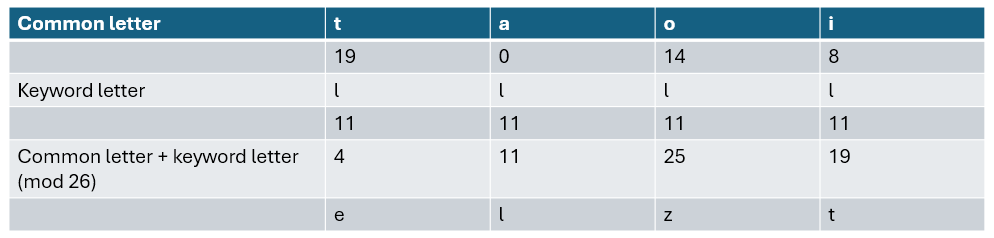

In [10]:
#| echo: false
#| label: Cracking-Vigenere-cipher-11
from IPython.display import Image, display
display(Image(filename='Cracking Vigenere cipher 11.png'))

Convieniently, these letters match up perfectly to what we found when we did a frequency analysis of every 5th letter in the ciphertext. Hence, the 5th letter in our keyword is 'l'.

Now to decrypt the entire keyword we have to repeat the process to find every other letter of the keyword. I would do this by taking off the first letter of the ciphertext and running the same code (then taking off the first and second letter of the ciphertext etc.). In our lesson I will not go through this process but I will include it here, but if you haev understood what we have done so far, then you can skip the next part.

When you do this process, you will get these results:

In [11]:
#| echo: false
text = "..."
n = 5

# Optional: keep letters only, as spaces/punctuation don't advance the key
text = "".join(c for c in text.upper() if c.isalpha())


ciphertext_letters = list(text[n - 1::n])


dictionary_letters = {}


for i in ciphertext_letters:
    if i in dictionary_letters:
        dictionary_letters[i]+=1
    else:
        dictionary_letters[i]=1

common_letters = sorted(dictionary_letters.items(), key=lambda x: x[1], reverse=True)[:10]

print(common_letters)


[('K', 907), ('Z', 638), ('G', 571), ('U', 527), ('T', 522), ('O', 479), ('N', 475), ('Y', 414), ('X', 406), ('R', 340)]


In [12]:
#| echo: false
text = "..."
n = 5

# Optional: keep letters only, as spaces/punctuation don't advance the key
text = "".join(c for c in text.upper() if c.isalpha())


ciphertext_letters = list(text[n - 1::n])


dictionary_letters = {}


for i in ciphertext_letters:
    if i in dictionary_letters:
        dictionary_letters[i]+=1
    else:
        dictionary_letters[i]=1

common_letters = sorted(dictionary_letters.items(), key=lambda x: x[1], reverse=True)[:10]

print(common_letters)


[('V', 930), ('K', 662), ('R', 568), ('Z', 525), ('F', 516), ('Y', 470), ('E', 458), ('I', 409), ('J', 405), ('U', 342)]


In [13]:
#| echo: false
text = "..."
n = 5

# Optional: keep letters only, as spaces/punctuation don't advance the key
text = "".join(c for c in text.upper() if c.isalpha())


ciphertext_letters = list(text[n - 1::n])


dictionary_letters = {}


for i in ciphertext_letters:
    if i in dictionary_letters:
        dictionary_letters[i]+=1
    else:
        dictionary_letters[i]=1

common_letters = sorted(dictionary_letters.items(), key=lambda x: x[1], reverse=True)[:10]

print(common_letters)


[('Y', 904), ('N', 599), ('U', 596), ('I', 539), ('C', 535), ('H', 513), ('B', 465), ('L', 406), ('M', 364), ('X', 351)]


In [14]:
#| echo: false
text = "..."
n = 5

# Optional: keep letters only, as spaces/punctuation don't advance the key
text = "".join(c for c in text.upper() if c.isalpha())


ciphertext_letters = list(text[n - 1::n])


dictionary_letters = {}


for i in ciphertext_letters:
    if i in dictionary_letters:
        dictionary_letters[i]+=1
    else:
        dictionary_letters[i]=1

common_letters = sorted(dictionary_letters.items(), key=lambda x: x[1], reverse=True)[:10]

print(common_letters)


[('I', 956), ('X', 606), ('E', 584), ('S', 560), ('M', 475), ('R', 470), ('L', 460), ('V', 433), ('W', 428), ('H', 342)]


We are going to guess that each of these common letters, 'K', 'V', 'Y' and 'I' all represent the plaintext letter 'e'. Now we need to work out which letters get 'K', 'V', 'Y', and 'I' to 'e' when we add them, and this will give us our keyword.

When you do this, you will get:

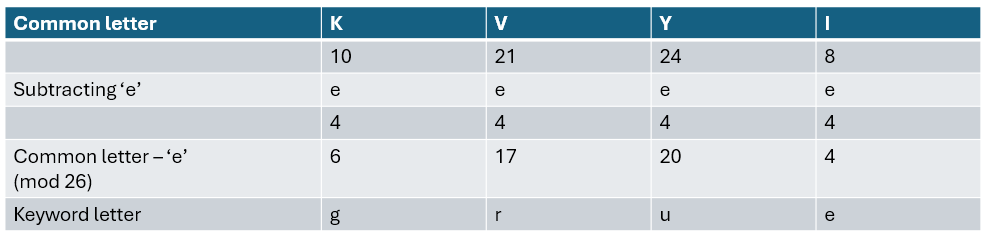

In [15]:
#| echo: false
#| label: Cracking-Vigenere-cipher-12
from IPython.display import Image, display
display(Image(filename='Cracking Vigenere cipher 12.png'))

We already know that our 5th letter in our keyword is 'l', so our final keyword is 'gruel'. When you decrypt the entire ciphertext you will find that this is an extract from Oliver by Charles Dickens, hence why I have used the keyword 'gruel'.